# DATA ANALYTICS
## Prepared by *ANG, Amanda*


### **Context**

**A significant number of hotel bookings are called off due to cancellations or no-shows.** Typical reasons for cancellations include change of plans, scheduling conflicts, etc. This is often made easier by the option to do so free of charge or preferably at a low cost. This may be beneficial to hotel guests, but it is a less desirable and possibly revenue-diminishing factor for hotels to deal with. Such losses are particularly high on last-minute cancellations.

The new technologies involving online booking channels have dramatically changed customers’ booking possibilities and behavior. This adds a further dimension to the challenge of how hotels handle cancellations, which are no longer limited to traditional booking and guest characteristics.

This pattern of cancellations of bookings impacts a hotel on various fronts:
1. **Loss of resources (revenue)** when the hotel cannot resell the room.
2. **Additional costs of distribution channels** by increasing commissions or paying for publicity to help sell these rooms.
3. **Lowering prices last minute**, so the hotel can resell a room, resulting in reducing the profit margin.
4. **Human resources to make arrangements** for the guests.

### **Objective**

This increasing number of cancellations calls for a Machine Learning based solution that can help in predicting which booking is likely to be canceled. INN Hotels Group has a chain of hotels in Portugal - they are facing problems with this high number of booking cancellations and have reached out to your firm for data-driven solutions. You, as a Data Scientist, have to analyze the data provided to find which factors have a high influence on booking cancellations, build a predictive model that can predict which booking is going to be canceled in advance, and help in formulating profitable policies for cancellations and refunds.


### **Data Description**

The data contains the different attributes of customers' booking details. The detailed data dictionary is given below:


**Data Dictionary**

* **Booking_ID:** Unique identifier of each booking
* **no_of_adults:** Number of adults
* **no_of_children:** Number of children
* **no_of_weekend_nights:** Number of weekend nights (Saturday or Sunday) the guest stayed or booked to stay at the hotel
* **no_of_week_nights:** Number of weekday nights (Monday to Friday) the guest stayed or booked to stay at the hotel
* **type_of_meal_plan:** Type of meal plan booked by the customer:
    * Not Selected – No meal plan selected
    * Meal Plan 1 – Breakfast
    * Meal Plan 2 – Half board (breakfast and one other meal)
    * Meal Plan 3 – Full board (breakfast, lunch, and dinner)
* **required_car_parking_space:** Does the customer require a car parking space? (0 - No, 1- Yes)
* **room_type_reserved:** Type of room reserved by the customer. The values are ciphered (encoded) by INN Hotels.
* **lead_time:** Number of days between the date of booking and the arrival date
* **arrival_year:** Year of arrival date
* **arrival_month:** Month of arrival date
* **arrival_date:** Date of the month
* **market_segment_type:** Market segment designation.
* **repeated_guest:** Is the customer a repeated guest? (0 - No, 1- Yes)
* **no_of_previous_cancellations:** Number of previous bookings that were canceled by the customer prior to the current booking
* **no_of_previous_bookings_not_canceled:** Number of previous bookings not canceled by the customer prior to the current booking
* **avg_price_per_room:** Average price per day of the reservation; prices of the rooms are dynamic. (in euros)
* **no_of_special_requests:** Total number of special requests made by the customer (e.g. high floor, view from the room, etc)
* **booking_status:** Flag indicating if the booking was canceled or not.

## **Importing the libraries required**

In [1]:
# Libraries to help with reading and manipulating data
import pandas as pd
import numpy as np

# Libaries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

# Importing the library for probaility distributions
import scipy.stats as stats

# Importing the Machine Learning models we require from Scikit-Learn
from sklearn.linear_model import LogisticRegression

# Importing the other functions we may require from Scikit-Learn
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import MinMaxScaler, LabelEncoder, OneHotEncoder

# To get diferent metric scores
from sklearn.metrics import confusion_matrix,classification_report,roc_auc_score,ConfusionMatrixDisplay,precision_recall_curve,roc_curve,make_scorer

# Code to ignore warnings from function usage
import warnings;
import numpy as np
warnings.filterwarnings('ignore')

### *Insights*
To successfully perform data analysis for INN Hotel Groups, importing the necessary libraries is the first step to setting up the environment. These are Python libraries that are particularly designed for data analytics, each with a distinct task. These libraries are Pandas, NumPy, Matplotlib, Seaborn, SciPy/scipy.stats, and Scikit-Learn. It is a common and acceptable practice in Python programming to have naming conventions like "pd" for Pandas, and "np" for NumPy, to save time on typing, avoid naming conflicts, and maintain consistent naming abbreviations in the codebase.

According to Rezek (2024), Pandas and Numpy are libraries for data manipulation and numerical calculations, respectively. Pandas and Numpy are important for different tasks like data cleaning, manipulation, and transformation, which are critical for ensuring the suitability of the data for modeling and analysis.

Matplotlib and Seaborn are used for data visualizations, to generate charts, graphs, and plots (GeeksforGeeks, 2020). Meanwhile, SciPy is a library for solving mathematical and scientific problems. In the code block, the package "scipy.stats" is used for probabilistic distributions and statistical operations. These libraries are important for the visualization of Exploratory Data Analysis (EDA) and useful for identifying patterns, exploring the datasets, and gaining insights into underlying relationships.

Skicit-Learn is a versatile machine-learning library for Python that provides dozens of tools for data preprocessing, model selection, model evaluation, and other utilities (Scikit Learn, 2024). From the "sklearn.linear_model" module, the logistic regression is imported, which is a machine learning model that is used for building predictive models for binary classification problems. Various utilities from the "sklearn.model_selection" model are imported including "train_test_split" for data splitting and "GridSearchCV" for hyperparameter tuning, streamlining the process of model optimization and selection. Another module from Skicit-Learn is "sklearn.preprocessing" wherein it imports utilities such as "MinMaxScaler", "LabelEncoder", and "OneHotEncoder". These utilities are crucial for preparing and transforming data for modeling tasks. The "sklearn.metrics" module is used to import evaluation metrics such as "confusion_matrix", "classification_report", "roc_auc_score", "plot_confusion_matrix", "precision_recall_curve", "roc_curve", and "make_scorer" to further evaluate the model's performance. Ultimately, Skicit-Learn is the backbone for building end-to-end machine learning systems that are extensively used by machine learning practitioners and data scientists.

Lastly, the "warnings" module is imported to ignore warnings from function usage. It provides very fine-grained control of the warning filters (Solanki, 2021).

## **PART 1**

## **Loading the dataset and creating a copy of it.**

In [2]:
hotel = pd.read_csv("C:\\Users\\jayar\\Downloads\\FINALS DA\\INNHotelsGroup.csv")

In [3]:
data = hotel.copy()

### *Insights*
"INNHotelsGroup.csv" is the file containing the dataset of the hotel bookings made by guests at the INN Hotel Group. With the use of the Pandas library, the contents of the dataset are read and created as a Pandas DataFrame called "hotel". The second line of code creates a copy of the DataFrame 'hotel' using the 'copy()' method from Pandas. This is done in order to perform data analysis and manipulation in a separate version to preserve the original dataset from unwanted modifications. 


## **Overview of the dataset**

### **View the first and last 5 rows of the dataset**

In [4]:
data.head()

,Booking_ID,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
0,INN00001,2,0,1,2,Meal Plan 1,0,Room_Type 1,224,2017,10,2,Offline,0,0,0,65.00,0,Not_Canceled
1,INN00002,2,0,2,3,Not Selected,0,Room_Type 1,5,2018,11,6,Online,0,0,0,106.68,1,Not_Canceled
2,INN00003,1,0,2,1,Meal Plan 1,0,Room_Type 1,1,2018,2,28,Online,0,0,0,60.00,0,Canceled
3,INN00004,2,0,0,2,Meal Plan 1,0,Room_Type 1,211,2018,5,20,Online,0,0,0,100.00,0,Canceled
4,INN00005,2,0,1,1,Not Selected,0,Room_Type 1,48,2018,4,11,Online,0,0,0,94.50,0,Canceled


In [5]:
data.tail()

,Booking_ID,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
36270,INN36271,3,0,2,6,Meal Plan 1,0,Room_Type 4,85,2018,8,3,Online,0,0,0,167.80,1,Not_Canceled
36271,INN36272,2,0,1,3,Meal Plan 1,0,Room_Type 1,228,2018,10,17,Online,0,0,0,90.95,2,Canceled
36272,INN36273,2,0,2,6,Meal Plan 1,0,Room_Type 1,148,2018,7,1,Online,0,0,0,98.39,2,Not_Canceled
36273,INN36274,2,0,0,3,Not Selected,0,Room_Type 1,63,2018,4,21,Online,0,0,0,94.50,0,Canceled
36274,INN36275,2,0,1,2,Meal Plan 1,0,Room_Type 1,207,2018,12,30,Offline,0,0,0,161.67,0,Not_Canceled


### *Insights*
The "head()" and "tail()" methods return a specified number of rows. The "head()" method returns the first rows while the "tail()" method returns the last rows. If the number is not specified in the parenthesis, the first or last five rows will be returned by default. 

In this case, "data.head()" returns the first 5 bookings, while "data.tail()" returns the last 5 bookings. Each booking made by a guest contains a column that represents the different attributes associated with the booking, including the number of adults, number of children, etc.

However, it is seen that the index starts with 0 instead of 1. This is because the index of a DataFrame in Python and other programming languages starts with 0 by default. This index states the position of each row within the DataFrame.

Overall, this code block shows how Pandas DataFrame methods are used to examine the content of the dataset and provide a quick overview of the first and last rows of data and its attributes. 

### **Understand the shape of the dataset**

In [6]:
data.shape

(36275, 19)

### *Insights*
In Pandas, the "data.shape" code indicates the dimensions or shape of the DataFrame by returning a tuple. It gives an understanding of the structure and size of the dataset that are useful for modeling, data analysis, and manipulation. In the parenthesis, the first number (36275) is the number of rows or observations in a DataFrame while the second number (19) is the number of attributes or columns in the DataFrame. In this case, the rows indicate the bookings, and the columns are the attributes associated with each booking in the DataFrame.

### **Check the data types of the columns for the dataset**

In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36275 entries, 0 to 36274
Data columns (total 19 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Booking_ID                            36275 non-null  object 
 1   no_of_adults                          36275 non-null  int64  
 2   no_of_children                        36275 non-null  int64  
 3   no_of_weekend_nights                  36275 non-null  int64  
 4   no_of_week_nights                     36275 non-null  int64  
 5   type_of_meal_plan                     36275 non-null  object 
 6   required_car_parking_space            36275 non-null  int64  
 7   room_type_reserved                    36275 non-null  object 
 8   lead_time                             36275 non-null  int64  
 9   arrival_year                          36275 non-null  int64  
 10  arrival_month                         36275 non-null  int64  
 11  arrival_date   

### *Insights*
The "info()" method provides a concise summary of information about the DataFrame. Starting at the top, the "RageIndex" shows the total number of entries (36275), ranging from index 0 to 36274. The "Data columns" show total number of columns in the DataFrame which is 19. The "Column" indicates the attribute or column name of the DataFrame. The "Non-Null Count" represents the number of non-values present in the column while the "Dtype" is the data type of the values in each column. This summary helps determine the presence of null or missing values on each attribute in the DataFrame and also provides an understanding of the data type of each. 

It is evident in the summary that all columns are labeled as "non-null", which means there are no missing values in the DataFrame. All of the columns have a count of 36275, which is the total number of entries, implying that all entries for each column don't have a null. Thus, it is more desirable to perform data analysis and modeling since there are no gaps in the data, making it more accurate and reliable. It also simplifies the data preparation process.

Subsequently, the data type is the format or classification that specifies the type of data that the column can hold and instructs the system how to interpret its value. It illustrates that the majority of the columns handle the data type "int64" which means the corresponding entries are integer numbers with 64 bits. Other data types in the DataFrame are "object" in 5 columns and "float64" in 1 column.

Lastly, the bottommost indicates the estimated memory usage of the DataFrame which is over 5.3 MB. 

Ultimately, 'data.info()' provides a comprehensive overview of the properties of a DataFrame such as the data types, column names, number of rows and columns, and memory usage. 

### **Checking duplicate values**

In [8]:
data.duplicated().sum()

0

### *Insights*
The ".duplicated()" function returns a boolean value (True or False) to check which rows in the DataFrame are duplicated or not. However, in this code block, the "sum()" is then applied to count the number of 'True' values in the boolean series, wherein it corresponds to the number of duplicated rows in the DataFrame. In boolean conversions, the 'True' value is equivalent to 1, and the 'False' value is equivalent to 0. 

Since the result is 0, it indicates that there are no duplicates. No duplicated rows imply that each row in the DataFrame is unique and doesn't have the exact same values in all columns. This is to ensure that there are no overlapping or redundant entries in the DataFrame.

### **Dropping the unique values column**

**Drop the `Booking_ID` column first before we proceed forward.**

In [9]:
data = data.drop(["Booking_ID"], axis=1)

### *Insights*
The ".drop" method is executed to drop or remove a row or columns by specifying the label names and corresponding axes. In this case, the "Booking ID" column is dropped in the DataFrame. The "axis=1" indicates to remove the column and not the row. The axis parameter allows for operations on either rows or columns, wherein the value '1' is represented by columns and '0' is represented by rows. This modified version is reassigned to the 'data' variable in order to update the DataFrame and utilize this on the succeeding codes, whereas it no longer contains the "Booking_ID" columns.

The "Booking_ID" is dropped since it serves as a unique identifier for each hotel booking. Therefore, it is deemed unnecessary for deriving meaningful insights and irrelevant for the analysis or modeling task at hand. This column does not inherently provide insights about patterns, relationships, or trends within the DataFrame. Thus, dropping it helps reduce unnecessary information for analysis. After dropping the 'Booking_ID', there are 18 columns left in the DataFrame. 

### **Check the summary statistics of the dataset and write your observations**

**Let's check the statistical summary of the data.**

In [10]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
no_of_adults,36275.0,1.844962,0.518715,0.0,2.0,2.00,2.0,4.0
no_of_children,36275.0,0.105279,0.402648,0.0,0.0,0.00,0.0,10.0
no_of_weekend_nights,36275.0,0.810724,0.870644,0.0,0.0,1.00,2.0,7.0
no_of_week_nights,36275.0,2.204300,1.410905,0.0,1.0,2.00,3.0,17.0
required_car_parking_space,36275.0,0.030986,0.173281,0.0,0.0,0.00,0.0,1.0
lead_time,36275.0,85.232557,85.930817,0.0,17.0,57.00,126.0,443.0
arrival_year,36275.0,2017.820427,0.383836,2017.0,2018.0,2018.00,2018.0,2018.0
arrival_month,36275.0,7.423653,3.069894,1.0,5.0,8.00,10.0,12.0
arrival_date,36275.0,15.596995,8.740447,1.0,8.0,16.00,23.0,31.0
repeated_guest,36275.0,0.025637,0.158053,0.0,0.0,0.00,0.0,1.0


### *Insights*
The ".describe()" method returns a numerical description or summary statistics for each column, showing the count, mean, standard deviation, minimum value, 25%, 50%, and 75% percentile, and the maximum value. All of these are types of statistics. According to ArcGis (2024), the definitions of  each statistic type are the following: 

* count - the number of values included in the calculations, excluding the null entries. 
* mean - the average of the field.  
* std/standard deviation - measures how spread out the values in the field. 
* min/minimum - the smallest value among all the records in the field. 
* max/maximum - the largest value among all the records in the field. 

**Percentiles:** - how a value compares to other values. 
* 25%/25th percentile - first quartile (Q1)
* 50%/50th percentile - median or second quartile (Q2) 
* 75%/75th percentile - third quartile (Q3)

There are a total of 14 columns to extract insights from. 
***
**Count**

The count statistic, 36,275, on each column or attribute in the dataset confirms that there are no missing values, since it was previously measured that there are 36,275 total entries in the entire DataFrame. This indicates that the dataset for INN Hotel Group is complete.
***
**Number of Adults and Number of Children**

The average number of adults per hotel booking is around 1.84, with a standard deviation 0.51. The percentiles being 2 support that the majority of the bookings consist of slightly fewer than 2 adults. A minimum of 0 and a maximum of 4 imply that the hotel bookings range from single adults to four adults. On the other hand, the number of children in the bookings is on average, very low (0.10), with a standard deviation of 0.40 and all percentiles showing 0. However, there is the presence of an extreme value, which is 10. The statistics suggest that the INN Hotel Group primarily caters to adult guests, either a pair of adults or solo travelers. While a very small portion of the bookings include children in their bookings. 
***
**Number of Weekend nights, Number of Week Nights, and Required Car Parking Space**

The lower average of weekend nights (0.81) than week nights (2.20), with 7th percentiles of 2 and 3, respectively, suggests that the majority of bookings are for short stays. However, the maximum of 7 for weekend nights and 17 for week nights means longer stays also occur. The 25th percentile of weekend nights (0) indicates that a significant portion of bookings do not involve weekends, while the 25th percentile for weekend nights (1) suggests that most of the bookings involve at least one week-long stay.Overall, there is a higher demand for week-long stays (Monday-Friday) compared to weekends (Saturday or Sunday). An average of 0.030 and 0 for the percentiles signifies that the majority of the guests do not need a car parking space for their hotel bookings. Being 1 as the maximum value indicates that the requirement for car parking is not particular among guests. This could be due to the location of the hotel or the targeted guests who prefer alternative transportation. 
***
**Lead Time, Arrival Year, Arrival Month, and Arrival Date**

Lead time averages approximately three months from the date of arrival but varies significantly due to outliers.The typical range of bookings falls between two weeks and four months, as seen in the percentiles. Some bookings are made at the last-minute, while others are done a year in advance. A diverse booking pattern is seen among guests, with guests booking ahead or booking close at the arrival date. However, the median shows that 50% of the data books at least 2 months before the arrival date.The arrival year statistics indicate that the majority of the bookings in the dataset are primarily between 2017 and 2018. Since all of the percentiles fall in 2018, it confirms that the majority of the bookings are from this year. For arrival months, the mean of 7.42 and percentiles from May to October suggest that there is a high concentration of bookings or peak season during the late summer and early fall/spring seasons. Perhaps it offers pleasant weather conditions for guests, making it an ideal time to book a hotel. On the arrival date, the mean is 15.59 and the median is 16, which implies that the bookings are concentrated around the middle of the month, despite diverse booking patterns (8.74). With a minimum value of 1 and a maximum of 31, it confirms that the bookings span the entire month. The median (16) is observed to be aligned with the mean arrival date, indicating a preference for staying in the second half of the month.
***
**Repeated Guests, Number of Previous Cancellations, and Number of Previous Bookings not Canceled**

The low mean value of repeated guests (0.0256) indicates that only 2.56% of the bookings are from repeated guests. All the percentiles indicate a value of 0, which implies that the significant majority of bookings are from new guests rather than repeated guests. It suggests that the hotel may have a hard time retaining customer loyalty. This is an area of improvement in which INN Hotel Group must take action. The mean of number of previous cancellations (0.02) shows that the majority of justs have very few previous cancellations. A minimum of 0 and a maximum of 13 implies that a small group of guests exhibits a high tendency toward cancellations, which must be further analyzed to identify the reasons. However, with all the percentiles being 0, it indicates that a significant portion of guests have had no previous cancellations. The number of bookings not canceled has a mean value of 0.15 and a median value of 0 suggesting that the majority of the guests do not have a significant history of previous bookings that were not canceled. However, the high standard deviation  and maximum of 58 mean some guests are highly active bookers, which potentially represent the repeated guests. Overall, the bookings are comprised of new guests, and cancellations happen on a few occasions. 
***
**Average Price Per Room and Number of Special Requests**

The average price per room is an average of €103.42, which can be considered a mid-range segment of the INN Group Hotel. The typical range of room prices is from €80.30 to €120. The presence of €0 can be due to complimentary offers, rewards, or compensation for issues or inconveniences experienced by guests during their stay. A presence of €540 room signifies an availability of luxury or premium room options for guests. On average, each booking has approximately one special request, although most bookings do not involve any special requests, as supported by the 25th percentile and median. With a standard deviation of 0.78 and a maximum of 5, some guests make more special requests than others. The 75th percentile value of 1 reveals that guests who make requests tend to have only a single request. This low number of special requests implies that guests are generally satisfied with the accommodations and do not have any further specific preferences, nonetheless, the hotel must be able to handle multiple requests as necessary.



## **Exploratory Data Analysis**

### **Univariate Analysis**

Let's explore these variables in some more depth by observing their distributions.

Define a **hist_box() function** that provides both a boxplot and a histogram in the same visual.

In [11]:
def hist_box(data,col):
  f, (ax_box, ax_hist) = plt.subplots(2, sharex=True, gridspec_kw={'height_ratios': (0.15, 0.85)}, figsize=(12,6))
  # Adding a graph in each part
  sns.boxplot(data[col], ax=ax_box, showmeans=True, orient='h')
  sns.distplot(data[col], ax=ax_hist)
  plt.show()

### *Insights*
This code block defines a Python function 'hist_box' that produces a combined plot of a box plot and histogram for a specific column in the DataFrame. It takes two parameters: 'data' (Pandas DataFrame) and 'col' (column name). This function relied on Seaborn and Matplotplib.pyplot libraries for the graphs to appear. Inside the function is the creation of the figures of the two subplots and ensuring that they have the right height, ratios, size, and orientation. 

* A boxplot is a graph that illustrates the distribution of numerical data and skewness by displaying the data percentiles and averages (Mcleodd, 2023). It shows a summary of a set of data, including the minimum, first quartile, median, third quartile, and maximum values. 
* A histogram is a graph that represents the distribution of data using rectangles with areas proportional to frequencies (Byju, 2017). 

These plots are useful for reviewing the data distribution of the dataset as well as understanding the skewness of the data, identifying outliers, and deriving insights. 

#### **Plot the histogram and box plot for the variable `Lead Time`.**

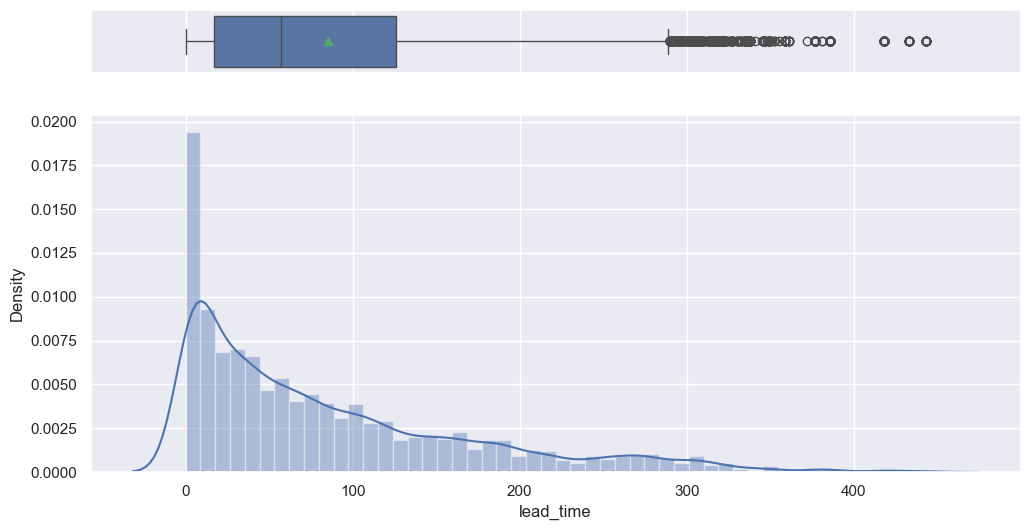

In [12]:
hist_box(data, 'lead_time') 

### *Insights*
The line calls the 'hist_box()' function to pass the 'data' and the 'lead_time' as arguments to the parameters declared. By calling the function, it effectively created and illustrated the box plot and histogram for the lead time column in the DataFrame. 

Lead time has several outliers. Any data point in the 'lead_time' that goes significantly beyond the 75th percentile (126 days) or over the upper whisker (443 days), is deemed to be an outlier. In this case, the box plot reinforces the observation drawn about outliers that are outside the upper boundary, wherein guests book their stay more than a year before the date of arrival. There are no outliers beyond the lower boundary or lower whisker. The median's proximity to the lower whisker implies that the median of the 'lead_time' skews towards the lower quartile, which indicates that a large portion of the data within the middle 50% is concentrated near the lower 25% of bookings. It also reveals that the distribution of the histogram is positively skewed, wherein most values are clustered around the left tail while the right tail of the distribution is longer. The positive skewness supports the observation that the lead time's mean and median are greater than zero. 


#### **Plot the histogram and box plot for the variable `Average Price per Room`.**

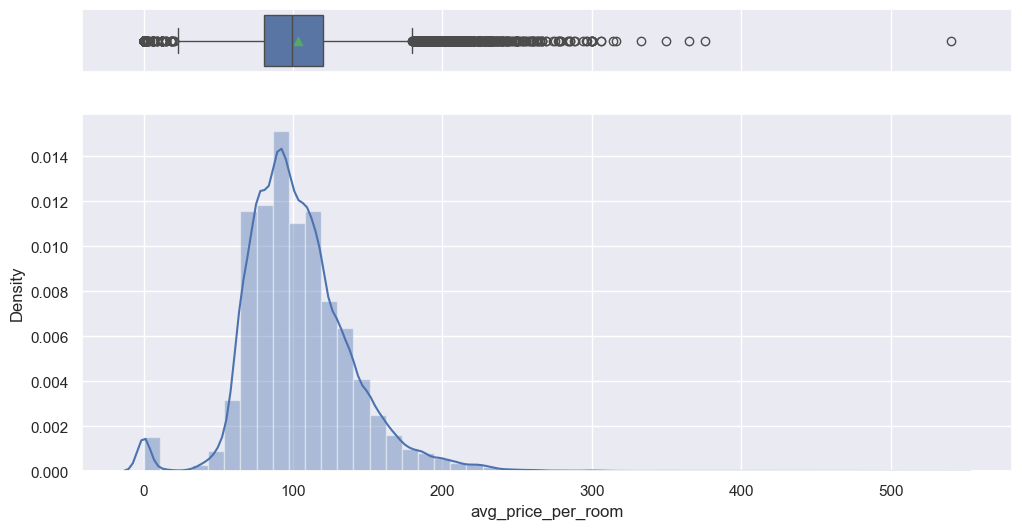

In [13]:
hist_box(data, 'avg_price_per_room')

### *Insights*
Similar to the previous code, the line calls the 'hist_box()' function, to pass the 'data' and the 'avg_price_per_room' as arguments to the parameters declared. By calling the function, it effectively created and illustrated the box plot and histogram for the 'avg_price_per_room' column in the DataFrame. 

It is evident in the box plot that there are outliers on both the upper and lower whiskers, which implies that some rooms are priced at a very low rate but some rooms are priced exceptionally high. It is also shown that the extreme outlier is diverted from the rest of the outliers and the box plot, which implies the price of this room is excessively high. This can be classified as one of the luxurious rooms that the hotel offers for guests, which is around €550. It could be a suite room that is good for four people. It is observed in the histogram that there are rooms that are priced at 0, which means it could be a complimentary stay for guests. Since there are a lot of outliers that have driven skewness in the graph, especially on the upper boundary, it is considered to be positively skewed. It is seen in the histogram that the typical room prices booked by guests are around €100.

**Interestingly some rooms have a price equal to 0.**

In [14]:
data[data['avg_price_per_room'] == 0]

,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
63,1,0,0,1,Meal Plan 1,0,Room_Type 1,2,2017,9,10,Complementary,0,0,0,0.0,1,Not_Canceled
145,1,0,0,2,Meal Plan 1,0,Room_Type 1,13,2018,6,1,Complementary,1,3,5,0.0,1,Not_Canceled
209,1,0,0,0,Meal Plan 1,0,Room_Type 1,4,2018,2,27,Complementary,0,0,0,0.0,1,Not_Canceled
266,1,0,0,2,Meal Plan 1,0,Room_Type 1,1,2017,8,12,Complementary,1,0,1,0.0,1,Not_Canceled
267,1,0,2,1,Meal Plan 1,0,Room_Type 1,4,2017,8,23,Complementary,0,0,0,0.0,1,Not_Canceled
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35983,1,0,0,1,Meal Plan 1,0,Room_Type 7,0,2018,6,7,Complementary,1,4,17,0.0,1,Not_Canceled
36080,1,0,1,1,Meal Plan 1,0,Room_Type 7,0,2018,3,21,Complementary,1,3,15,0.0,1,Not_Canceled
36114,1,0,0,1,Meal Plan 1,0,Room_Type 1,1,2018,3,2,Online,0,0,0,0.0,0,Not_Canceled
36217,2,0,2,1,Meal Plan 1,0,Room_Type 2,3,2017,8,9,Online,0,0,0,0.0,2,Not_Canceled


In [15]:
data.loc[data['avg_price_per_room'] == 0, "market_segment_type"].value_counts()

market_segment_type
Complementary    354
Online           191
Name: count, dtype: int64

### *Insights*
The 'data[data['avg_price_per_room'] == 0]' is executed to filter the rows in the DataFrame (data) of the column 'avg_price_per_room' wherein the values are equal to 0, then display the DataFrame with those respective rows. This is a common function in Pandas for data manipulation and analysis.

The 'data.loc[data['avg_price_per_room'] == 0, "market_segment_type"].value_counts()' is done to return the counts of unique values in descending order wherein the first element has the most frequencies.

Based on the output, the Complementary market segment contains 354 bookings out of the total bookings, while the Online market segment is 191. It is seen that the columns are composed of the data type integer with 64 bits. 

As stated, the illustrated DataFrame contains 545 rows which means there are 545 bookings that have booked a free room. There are many potential reasons why some rooms are priced at 0 or listed as free.

* Based on the first and last rows displayed, most of the bookings belonged to the "Complementary" market segment type, which means that these rooms were offered at 0 cost as a complimentary offer. 
* On the table, the presence of repeated guests can also be a reason to offer a complimentary room for a loyal guest. Similarly, the number of previous bookings not canceled can be a reason to offer them a complimentary room since they recognized their repeated bookings, which reflects their satisfaction with the hotel accommodation.
* Along with the Complementary, another prevalent market segment type is "Online". The INN Hotel Group is most likely to have special offers or huge deals for online bookings, where the rooms are provided at the lowest cost or a complimentary room is offered. This can be one of their ways to promote their hotel on the digital channel. 
* Since most of the guests are single adults, it could be a high-valued or influential guest wherein it is offered at a complementary stay as a form of VIP treatment. 
* On low-demand months, this could be one of their effective ways to attract customers so that they can maximize the revenue from some of their hotel facilities or services during their stay. 


**Checking the Inter-Quartile Range.**

In [16]:
Q1 = data["avg_price_per_room"].quantile(0.25)

Q3 = data["avg_price_per_room"].quantile(0.75)

IQR = Q3 - Q1 

Upper_Whisker = Q3 + 1.5 * IQR
Upper_Whisker

179.55

In [17]:
data.loc[data["avg_price_per_room"] >= 500, "avg_price_per_room"] = Upper_Whisker

### *Insights*
This code has demonstrated how to calculate the value of the 'Upper_Whisker'. The upper whisker is used in box plots that represent the highest value within the dataset that is not considered an outlier (Tableau, 2017). It is the largest dataset number that is smaller than 1.4 times the IQR above the third quartile. 

The first line of code computes the first quartile (Q1) of the 'avg_price_per_room' column, wherein it is the 25th percentile of the data. While the second line computes the third quartile (Q3), which is the 75th percentile of the data. The Interquartile range (IQR) is the range of values that sits in the middle of the scores. It is the range for the middle 50% of the sample. Statisticians find it useful for measuring variability. It follows the formula Q3 - Q1. 

In this case, Q1 is subtracted from Q3 to get the IQR in 'avg_price_per_room'. To get the upper whisker, Q3 is added to 1.5 and multiplied by the IQR. The result is 179.55. On the last line, it replaces the values that are greater than or equal to 500 with the upper whisker which is 179.55 of the 'avg_price_per_room' column. This is done by capping all the values in the column that are greater or equal to 500 to the value of the upper whisker in order to reduce the effect of outliers on the data analysis. 

#### **Let's understand the distribution of the categorical variables**

**Number of Children**

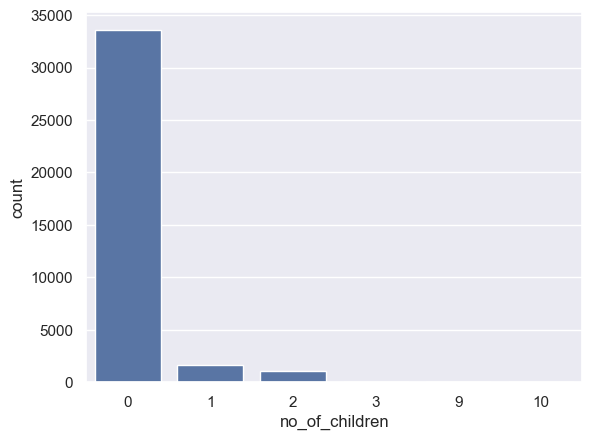

In [18]:
sns.countplot(x='no_of_children', data=data)
plt.show()

In [19]:
data["no_of_children"].value_counts(normalize=True)

no_of_children
0     0.925624
1     0.044604
2     0.029166
3     0.000524
9     0.000055
10    0.000028
Name: proportion, dtype: float64

In [20]:
data["no_of_children"] = data["no_of_children"].replace([9, 10], 3)

### *Insights*

A count plot is a visualization that reveals the counts of observations in each categorical bin and displays the results as a bar chart (GeeksforGeeks, 2020). Bar plots and count plots may look similar, but bar plots show the mean of a quantitative variable among observations in each category (Loves, 2021). 

The first line is executed to create a count plot with the use of the Seaborn library. This bar plot will illustrate the counts of observations in the 'no_of_children' column of the DataFrame. The height of the bar corresponds to the value's number of occurrences. Matplotlib/plt is used to display the graph.

The second line computes the frequencies of unique values in the no_of_children column. By setting 'normalize=True', the function provides proportions to the counts, which means that the output of these decimal values is between 0 and 1 and represents the percentage of the total.

In the last line, it implies that all the occurrences of values 9 and 10 are replaced by 3 in the 'no_of_children' column. It is a way to handle outliers or aggregate categories for data analysis. By doing this, it consolidates the data into a more workable form and a more normalized state for statistical analyses. This suggests the usefulness of data cleaning and data normalization for analysis. 

The count plot clearly illustrates that the value of 0 in the 'no_of_children' column holds the vast majority of the bookings. There are a small number of bookings with one or two children, but these occurrences are infrequent.

The next line of code shows the proportion instead of the raw counts of each value in the 'no_of_children' column, which is arranged in descending order. There are a total of six values with their corresponding proportions. For instance, it is shown that about 92.56% (0.925624) of the rows have a value of 0 for the number of children. Therefore, the value of 0 holds the largest proportion among the other values in the 'no_of_children' column in the dataset. Next in the proportion is the value of 1, which is roughly 4.46% (0.44604) of the rows, and so on. The analysis reveals that in most cases, about 93% of the bookings involve adults without children. The values of 10 and 9 have the lowest proportion within the distribution among all the values. If all of the proportions are summed up, it will always be equal to 1 or 100%. This helps in interpreting and comparing the relative frequencies of each value in the column. 

**Arrival Month**

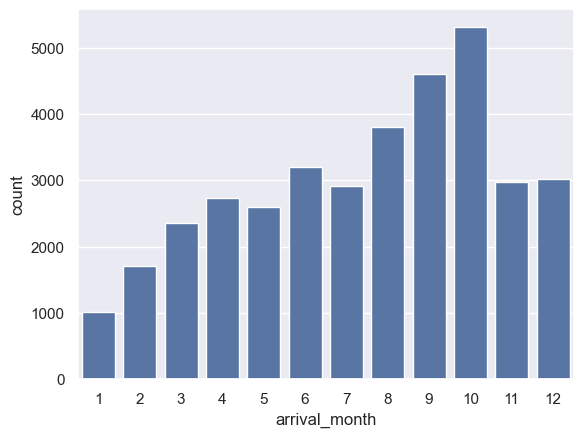

In [21]:
sns.countplot(x="arrival_month", data=data)
plt.show()

In [22]:
data["arrival_month"].value_counts(normalize=True)

arrival_month
10    0.146575
9     0.127112
8     0.105114
6     0.088298
12    0.083280
11    0.082150
7     0.080496
4     0.075424
5     0.071620
3     0.065003
2     0.046975
1     0.027953
Name: proportion, dtype: float64

### *Insights*

The output visualizes the count plot of the 'arrival_months', which are the months in numeric form at the x-axis from the DataFrame. The count plot illustrates that there is an increasing demand for bookings between May and October, however, the demand significantly decreased as the last and early months of the year passed. It is evident that the highest peak/count of observations is in October which is beyond 5,000 bookings. This means that October stands out as the busiest month for the INN Hotel Group. Followed by October, there is also a high concentration in September with roughly 4,600 bookings, and also considering the month of August with 3,800 bookings. When combined, these 3 months make up about more than 35% of the bookings. On the other hand, there is a clear view that there are low-demand periods which are the months of January to April and the last two months of the year. The months with the lowest concentration of bookings is January with only 1,000 bookings, followed by February, March, and April. The hotel can offer promos or deals in these months, including New Year promos. 

The output on the second line is similar to the previous code for displaying the proportion of a column in a dataset. In this case, the proportion or normalized counts of the 'arrival_month' is displayed. There are a total of 12 values with their corresponding proportions. It is evident in the output that the value of 10 holds the largest proportion for about 14.65% of the rows in the 'arrival_month' which corresponds to October. However, the succeeding proportions seem to be close to each other in comparison to the previous output of 'no_of_children, which means the arrival month for bookings greatly varies from each other. The highest proportions are in August (10.51%), September (12.71%), and October (14.65%), which may indicate peak arrivals. The lowest proportions are in the early months such as January (2.79%), February (4.69%), and March (6.50%), implying there are fewer arrivals during that period. As expected, the proportions always sum up to 1 or 100%. 

**Booking Status**

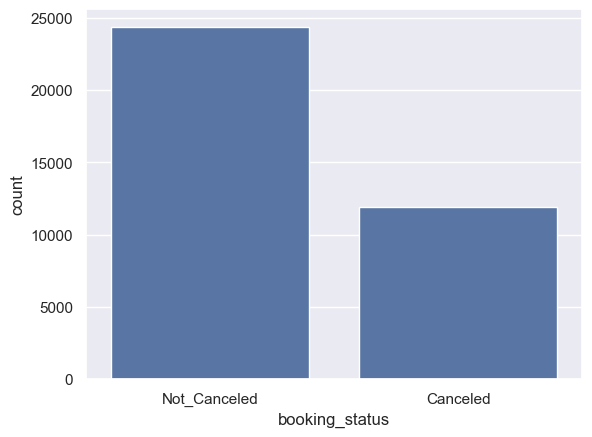

In [23]:
sns.countplot(x="booking_status", data=data)
plt.show()

In [24]:
data['booking_status'].value_counts(normalize=True)

booking_status
Not_Canceled    0.672364
Canceled        0.327636
Name: proportion, dtype: float64

### *Insights*

The first line creates a count plot for the 'booking_status' column from the DataFrame. It is observed that there is a significant difference between the 'Canceled' and 'Not_Canceled' columns. It is shown that there are a high number of bookings that are not canceled which is assumingly around 24,000. However, there is a notable prevalence of canceled bookings, at around 13,000, which is less than half of the not canceled bookings. The number of canceled bookings signifies the importance of addressing this concern in order to prevent it from further rising to half of the total bookings which is disadvantageous for the hotel. 

The second line of the code analyzes the proportions of the values in the column 'booking_status'. It only reveals two categorical variables: 'Not_Canceled' and 'Canceled'. The results show that not- canceled bookings make up about 67.24%, while canceled bookings make up 32.76%. It is evident that the bookings that are not canceled constitute the majority; however, this does not mean that the hotel will ignore the cancellations. It is worth noting that the cancellation rate of 32.76% is quite high for the hotel industry. The INN Hotel Group must further investigate the reason behind these cancellations and take action on how they can minimize them to improve guest satisfaction and boost their revenue. The hotel can probably build better customer relationships or implement policies to lower the percentage of cancellations, making it more manageable. 

**Let's encode Canceled bookings to 1 and Not_Canceled as 0 for further analysis**

In [25]:
data["booking_status"] = data["booking_status"].apply(
    lambda x: 1 if x == "Canceled" else 0
)

### **Bivariate Analysis**

#### Find and visualize the correlation matrix using a heatmap and write your observations from the plot.



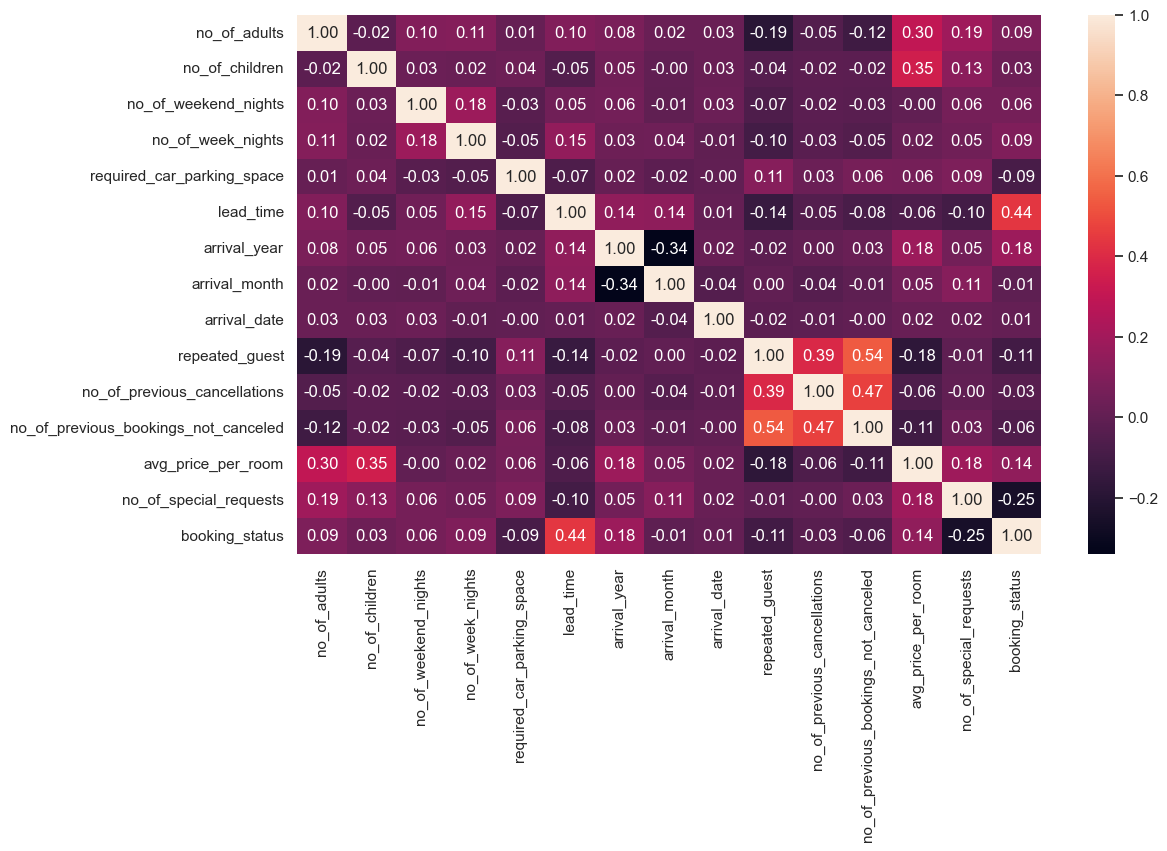

In [26]:
non_numeric = data.select_dtypes(include=object).columns.tolist()

data_numeric = data.drop(non_numeric, axis=1)

plt.figure(figsize=(12, 7))
sns.heatmap(data_numeric.corr(), annot=True, fmt=".2f")
plt.show()


### *Insights* 
The first line of the code converts an array to an ordinary list with the 'tolist()' function from Pandas, assigning to a variable 'non_numeric'. In this case, the column names that have the data type 'object' from the DataFrame will be listed. These columns or variables contain non-numeric values (like strings) that are not appropriate for heatmaps unless transformed. The heatmap is commonly used to display a generalized view of the numeric values for visualizing the correlation matrix of multiple variables (Super User, 2020).

Therefore, in the second line of code, it drops the columns listed in the 'non_numeric' variable from the DataFrame. The 'axis=1' implies that columns should be dropped. It will then be assigned to the 'data_numeric' variable that doesn't have non-numeric columns. In this case, the columns 'market_segment_type', 'room_type_reserved, and 'type_of_meal_plan' are dropped, which left the heatmap with 15 columns to correlate with each other. 

The third line specifies the size of the figure which is 12 inches by 7 inches. The fourth line creates the heatmap with the use of the Seaborn library. The function 'data_numeric.corr()' is used to find the correlations of each column in the DataFrame. The 'annot' is an attribute that is used in the heatmap() to determine whether to write the data value in each cell of a heatmap (Seaborn, 2024). Since the annot is True, the text will be written on each cell in the heatmap. The 'fmt=".2f"' signifies 2 decimal places (.2f) with floating point representation (f portion).

A heatmap is a visualization where values are depicted by color to show the relationships between two variables (Kenton, 2022). In this case, the heatmap illustrates the correlation between the variables or columns in the DataFrame. The correlation ranges from -1 to +1. A value that is closer to zero means there is a weak or no correlation between the two variables, while a value closer to 1 means there is a strong positive correlation (Nickolas, 2023). A value that is closer to -1 indicates a strong negative correlation. In the heatmap, there is no perfect negative correlation (-1) or strong negative correlation.

At first glance, there is a pattern of light color in the center diagonal of the heatmap, which means there is a strong correlation between those variables (1.0). However, the x-axis and y-axis reveal that the two variables are the same as each other, so we cannot give any insights. 

**Negative Correlation:** 
All of the relationships are somehow classified as having a weak negative correlation.
* 'arrival_month' and 'arrival_year' (-0.34) - It implies that there is a weak negative correlation between the variables. The arrival month does not affect the values of the arrival year of the bookings, and vice versa. 
* 'booking_status' and 'no_of_special_requests' (-0.25) - It reveals that there is a weak negative correlation between the number of special requests a guest makes and whether they will cancel their booking or not.
* 'repeated_guest' and 'no_of_adults' (-0.19) - It suggests that the number of adults in a booking does not represent any meaningful relationship based on whether a guest is a repeated guest or not, and vice versa. The correlation value exhibits an extremely weak negative correlation.  

**Positive Correlation:**
All of the relationships are somehow classified as having a moderately positive correlation.
* 'no_of_previous_bookings_not_cancelled' and 'repeated_guest' (0.54) - It is highly unlikely that a repeated guest will cancel a booking since, presumably, they have had a positive experience that has earned their trust in the hotel. Therefore, there is a clear trend that guests with a record of non-canceled bookings are more likely to be repeated guests.  
* 'no_of_previous_bookings_not_cancelled' and 'no_of_previous_cancellations' (0.47) - It is most likely that guests that have not canceled their bookings previously have also had fewer previous cancellations. This makes sense since guests who complete their stay are less likely to cancel. 
* 'lead_time' and 'booking_status' (0.44) - The lead time and booking status moderately influence each other since, for example, a guest who booked in advance tends to be more committed to their trip since they have probably planned it well and the hotel has secured the confirmation of their booking. While lower lead times, like walk-ins, might face last-minute problems with their bookings and may lead to cancellations. So it makes sense that lead time and booking status have a positive correlation. 

**Hotel rates are dynamic and change according to demand and customer demographics. Let's see how prices vary across different market segments**

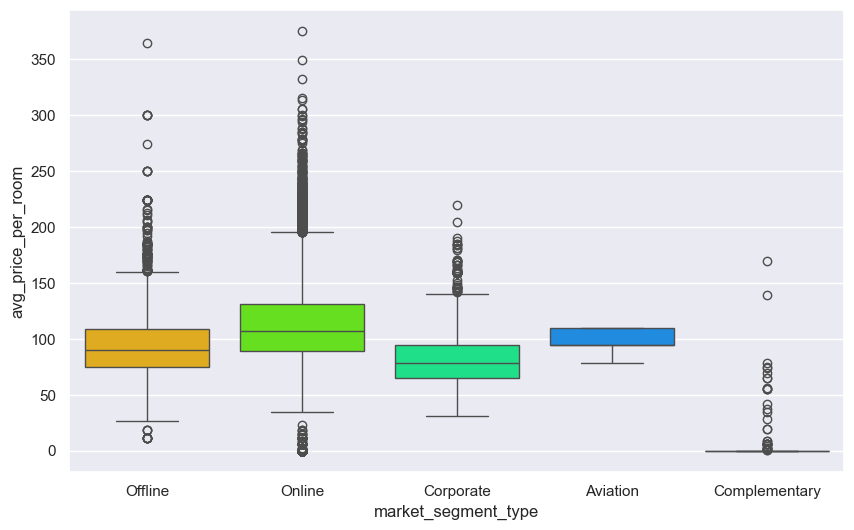

In [27]:
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=data, x="market_segment_type", y="avg_price_per_room", palette="gist_rainbow"
)
plt.show()

### *Insights*
The code block creates a box plot by using Matplotlib and Seaborn to visualize the distribution of the average price per room in terms of booking method. The booking method of a guest is classified as a marketing segment type. The type of market segment on in the x-axis, while the average price per room is on the y-axis.

* The Online market segment exhibits the most outliers, which indicates a broader range of prices, wherein some are priced extremely high and some are extremely low. This is most likely due to the presence of third-party travel websites or platforms that offer diverse prices for the same room type at the hotel. The outliers suggest that the online segment has booked the most expensive room, which could be very luxurious, and also the cheapest room where there could be free rooms as a complimentary offer.
* Despite the outliers, the room prices in most market segments aren't really distant from each other. The majority, which is represented by the middle half of the box (IQR), signifies that prices for these rooms are below €150.
* It is noteworthy that the minimum prices for all market segments except Aviation are below €50. While aviation bookers have a slightly higher minimum price, around €80. 
* The maximum value or upper whisker of all the market segments did not go beyond €200. 
* It is sensible that Complementary market segment are booked with the lowest prices for the rooms.
* The booking prices for Aviation segment mostly sit around 100 euros, with no outliers or maximum value exceeding around 130 euros. This implies that Aviation has the most limited price variation for bookings. 
* The corporate booking prices are generally lower than the offline and online bookings. It is most likely that the hotel has secured discounted rates for bulk bookings for corporations at pre-negotiated rates, which are different from the publicly available rate. However, there are still outliers on the upper boundary, possibly resembling corporate bookings in luxurious types of rooms. 

We will define a **stacked barplot()** function to help analyse how the target variable varies across predictor categories.

In [28]:
# Defining the stacked_barplot() function
def stacked_barplot(data,predictor,target,figsize=(10,6)):
  (pd.crosstab(data[predictor],data[target],normalize='index')*100).plot(kind='bar',figsize=figsize,stacked=True)
  plt.legend(loc="lower right")
  plt.ylabel('Percentage Cancellations %')

### *Insights*
The code block defines a function of the 'stacked_barplot', taking four parameters such as 'data', 'predictor', 'target', and 'figsize'. The predictor is a variable whose values are utilized to predict the value of the target variable. The figsize is the attribute that adjusts the width and height. Inside the function, it uses 'pd.crosstab()' to calculate a simple cross-tabulation of two factors. In other words, it creates a stacked bar plot wherein each bar represents a category from the DataFrame. The y-axis displays the percentage scale from 0 to 100%. 

#### Plot the stacked barplot for the variable `Market Segment Type` against the target variable `Booking Status` using the stacked_barplot  function provided and write your insights. 

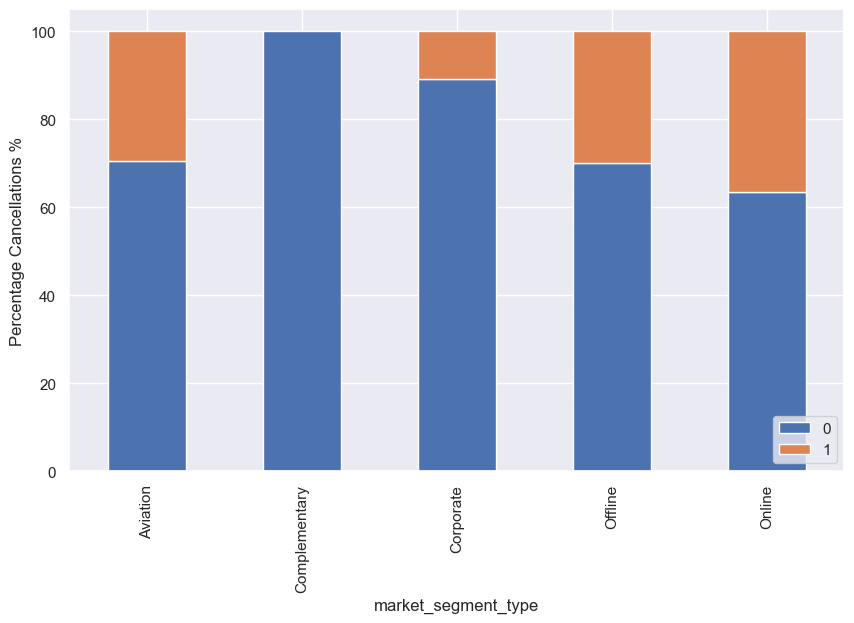

In [29]:
# Remove _________ and complete the code
stacked_barplot(data, "market_segment_type", "booking_status")

### *Insights*
The code calls the function 'stacked_barplot' and passes the arguments 'market_segment_type' and 'booking_status' to the function in order to be plot on the graph . 

* It is observed that there are 0% cancellations for a Complementary stay. Therefore, it is proven that guests receiving complementary stays are never likely to cancel their booking, which is sensible. 
* Followed by Complementary, Corporate bookings have the lowest cancellation rate, with only 10%. This is likely because these bookings are often for a business trip arranged by a company with a dedicated budget and company approval. It could also be a leisure trip sponsored by the company as an incentive. These reasons support why corporate bookings are less likely to be canceled.
* Both Offline (email, walk-in, phone calls) and Aviation bookings have similar cancellation rates, around 30%. These types have a low risk of cancellation, given the data for the number of adults, there are typically 1-2 adults per booking. Assuming, it could be travelers who are few or single individuals with less commitment compared to corporate bookings. There could be unforeseen circumstances or personal emergencies behind these cancellations on both segments. In Aviation, it could be flight delays or sudden cancellations of flights that disrupt their travel plans, leading them to cancel their hotel booking. In offline, it could be the uncertainty that they don't have enough details or a full picture of the room type and accomomdation compared to online details, leading to cancellations if expectations are not met. 
* Lastly, Online bookings have the highest cancellation rate, almost 40%, which could be attributed to a lot of factors. Online booking platforms have a simpler and easier cancellation processes compared to offline methods, and in some cases, free cancellation. Travelers can book online without any strong commitment, just for the case to reserve a room and then find other options, knowing they can easily cancel later. On third-party websites and platforms, there is a vast number of choices of hotels and their corresponding amenities, guest reviews, and prices to choose from, so online bookers will keep searching for the best deal, which can lead them to cancel existing bookings. Some travelers may base their decision on online photos and descriptions, but upon arrival, the reality doesn't match their expectations.

#### Plot the stacked barplot for the variable `Repeated Guest` against the target variable `Booking Status` using the stacked_barplot  function provided and write your insights.

Repeating guests are the guests who stay in the hotel often and are important to brand equity.

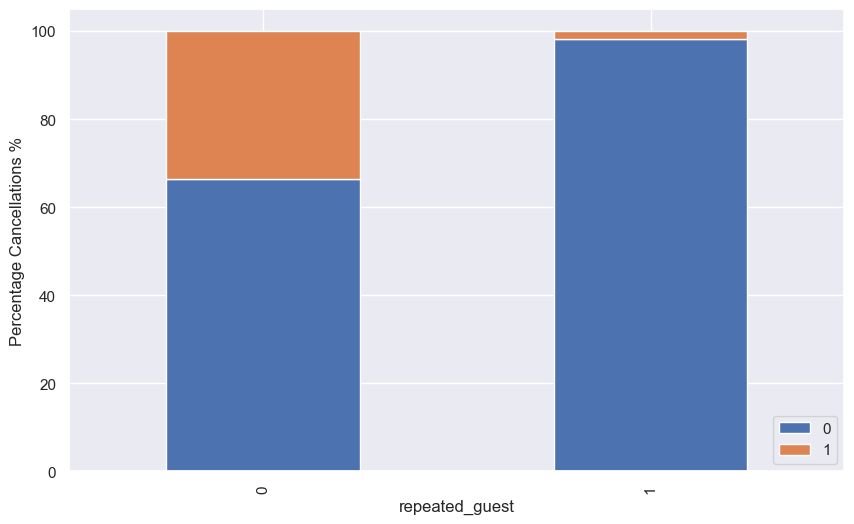

In [30]:
stacked_barplot(data, "repeated_guest", "booking_status")

### *Insights*
The code calls the function 'stacked_barplot' and passes the arguments 'repeated_guest' and 'booking_status' to the function in order to plot the graph . 

* It is seen that repeated guests are highly unlikely to cancel, whereas only a very small percentage of bookings have been cancelled, around 2%. A reason for these few cancellations can be due to emergencies or crucial circumstances that force them to cancel their booking. Other than that, the majority of the repeated guests did not cancel their bookings, perhaps because of their positive experience with the accommodation. 
* It is seen that most cancellations are from first-time or new guests in the hotel, around 30%. Since they are not familiar with the hotel and have experienced it firsthand, there is a higher likelihood that they will cancel it. There are other reasons why new guests cancel their bookings.


**Let's analyze the customer who stayed for at least a day at the hotel.**

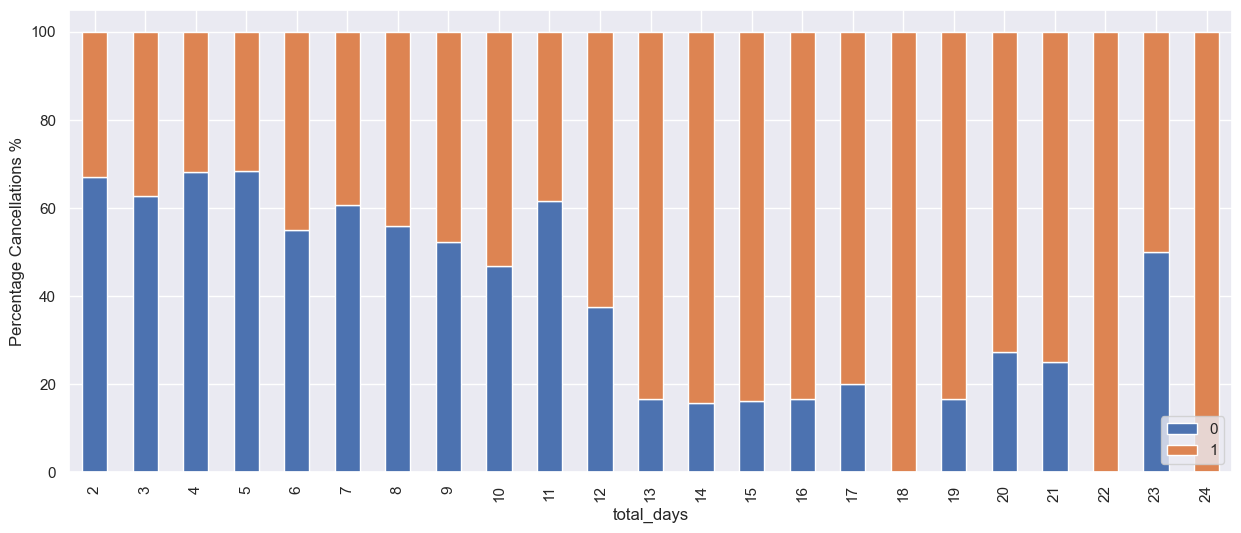

In [31]:
stay_data = data[(data["no_of_week_nights"] > 0) & (data["no_of_weekend_nights"] > 0)]
stay_data["total_days"] = (stay_data["no_of_week_nights"] + stay_data["no_of_weekend_nights"])

stacked_barplot(stay_data, "total_days", "booking_status",figsize=(15,6))

### *Insights*
The code block creates a stacked bar plot that shows the distribution of the booking statuses based on the total days that guests stayed. The stacked bar plot is only interested in bookings where guests stay for at least one night. This visualization helps analyse the booking data and interpret the relationship between the total length of stay and booking status. 

* There is a trend that as the guest's length of stay or total days increases, the chances of cancellations also increase. The first few days already have cancellations but they are fewer than in the second half of the month. Starting at the 13th day, cancellations have significantly risen, as on the 13th, 14th, and so forth of the month. The 18th, 22nd, and 24th days have a 100% cancellation rate, which is worrisome. Longer stays are harder to commit to since there are unexpected plans or certain circumstances that may arise, especially for leisure travelers, which could result in cancellations. It is also difficult to commit because there is a greater cost and more investment in the traveler's time. As longer stays are priced higher, guests are likely to cancel them due to financial constraints, so they will check other alternative options. Perhaps it could be the lack of amenities or services for guests that would accommodate their longer stay, leading them to cancel it. It is alarming to see these cancellations occurring; therefore, the hotel must take action by enhancing their accommodations and collecting feedback from guests, especially those with longers stays to avoid further cancellations. 

**As hotel room prices are dynamic, Let's see how the prices vary across different months**

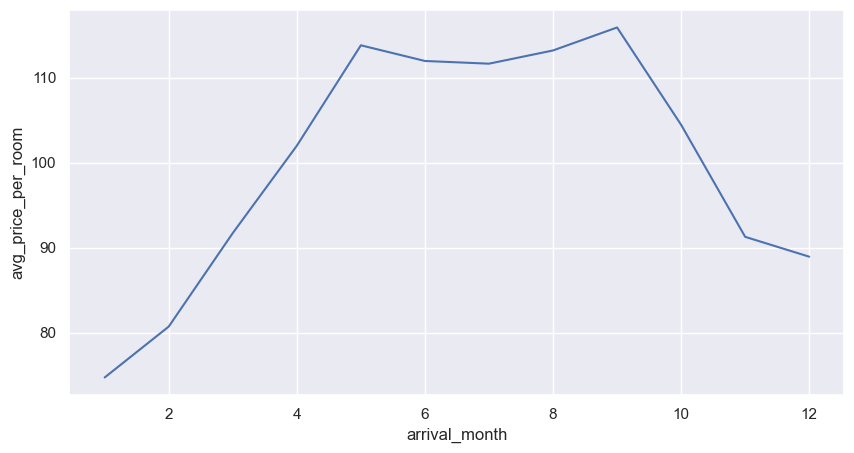

In [32]:
plt.figure(figsize=(10, 5))
sns.lineplot(y=data["avg_price_per_room"], x=data["arrival_month"], ci=None)
plt.show()

### *Insights*
The code block creates a line plot that visualizes the average price per room on different arrival months to observe the trend over time. 

* The first two months, January and February, indicate that the room prices are set very low, around €70 and €80, respectively. 

* There is a trend that as the months pass, the prices significantly increase and remain somewhat stable from May to September, with high prices compared to the rest of the months.  

* September has the highest peak of room prices, about €115. Following September, it would be May that has a higher room price, which is close to the value of September. However, as September passes, the room prices decrease until December, which is around €89.

* Based on the data earlier from the bar plot of the arrival months, October is the peak month. It could be due to several fun events or activities that month. However, the rooms prices are not really that high, due to the fact that the hotel wants to lower prices in the busiest month to fill those unbooked rooms. September has the highest price since some people tend to book their October stays last-minute, given that September is the closest month to October, so the hotel will increase their prices in September to take advantage of this last-minute rush. 

## **Data Preparation for Modeling**

- We want to predict which bookings will be canceled.
- Before we proceed to build a model, we'll have to encode categorical features.
- We'll split the data into train and test to be able to evaluate the model that we build on the train data.

**Separating the independent variables (X) and the dependent variable (Y)**

In [33]:
X = data.drop(["booking_status"], axis=1)
Y = data["booking_status"]

X = pd.get_dummies(X, drop_first=True)

**Splitting the data into a 70% train and 30% test set**

In [34]:
# Splitting data in train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.30,stratify=Y, random_state=1)

In [35]:
print("Shape of Training set : ", X_train.shape)
print("Shape of test set : ", X_test.shape)
print("Percentage of classes in training set:")
print(y_train.value_counts(normalize=True))
print("Percentage of classes in test set:")
print(y_test.value_counts(normalize=True))

Shape of Training set :  (25392, 27)
Shape of test set :  (10883, 27)
Percentage of classes in training set:
booking_status
0    0.672377
1    0.327623
Name: proportion, dtype: float64
Percentage of classes in test set:
booking_status
0    0.672333
1    0.327667
Name: proportion, dtype: float64


### *Insights*
The entire code block is an important step for building and assessing a machine learning model. The training data is the biggest subset of the original dataset, which is used to train the machine learning model (JavaTPoint, 2021). Meanwhile, the test data is another subset of the original data that is independent of the training dataset. This data is used to check the accuracy of the model. 

The first code block creates a new DataFrame, X, by dropping the column "booking_status" from the original DataFrame. Then, the Y variable contains a DataFrame that only has the target variable, which is "booking_status". The '.get_dummies()' method is used for data manipulation, converting the categorical data into dummy variables (GeeksforGeeks, 2020). This code block is the initial step in data preparation for splitting the data into training and test sets.

The second code block splits the data with the use of the 'train_test_split' method from the skicit-learn library. It specifies that 30% of the data is used for testing and 70% is used for training the machine learning model. The training data typically has a greater percentage than the testing data so  the machine learning model can learn more meaningful patterns and be much effective. Other parameters in 'train_test_split' include 'random_state', 'stratify', and 'test_size'. The 'stratify' argument is used to ensure that the class distribution is preserved in both sets and also to avoid biases. The print statements show the results of the datasets and proportions of classes (0 for not canceled and 1 for canceled) in both sets. 

* The output shows that the training set has 25,392 samples and 27 features, while the test set has 10,883 samples and 27 features. 
* In the training set, the percentage of class 0 (not canceled) is 67.24%, while the percentage of class 1 (canceled) is approximately 32.76%. Similarly, the test set has 67.23% and 32.77% for classes 0 and 1, respectively.  

The output appears to have a large imbalance in the distribution, wherein there are more instances of class 0 than class 1, which could impact predictive model's performance. It could be inherently the original data itself. Stratified sampling is helpful, but it cannot completely eliminate the imbalanced class.  

## **Model Evaluation Criterion**

#### **Model can make wrong predictions as:**

1. Predicting a customer will not cancel their booking but in reality, the customer will cancel their booking.
2. Predicting a customer will cancel their booking but in reality, the customer will not cancel their booking. 

#### **Which case is more important?** 

Both the cases are important as:

* If we predict that a booking will not be canceled and the booking gets canceled then the hotel will lose resources and will have to bear additional costs of distribution channels.

* If we predict that a booking will get canceled and the booking doesn't get canceled the hotel might not be able to provide satisfactory services to the customer by assuming that this booking will be canceled. This might damage brand equity. 



#### **How to reduce the losses?**

* The hotel would want the `F1 Score` to be maximized, the greater the F1  score, the higher the chances of minimizing False Negatives and False Positives. 

**Also, let's create a function to calculate and print the classification report and confusion matrix so that we don't have to rewrite the same code repeatedly for each model.**

In [36]:
# Creating metric function 
def metrics_score(actual, predicted):
    print(classification_report(actual, predicted))
    # Creates visualised confusion matrix
    cm = confusion_matrix(actual, predicted)
    plt.figure(figsize=(8,5))
    # Creates a heatmap correlating variables with the cancellation of flights
    sns.heatmap(cm, annot=True,  fmt='.2f', xticklabels=['Not Cancelled', 'Cancelled'], yticklabels=['Not Cancelled', 'Cancelled'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.show()

### *Insights*
A predictive model can make mistakes, and in the context of hotel booking cancellations, these mistakes are crucial. We want to avoid using our model to predict that a booking will not cancel, but in reality, it will cancel, and vice versa. These mistakes have several consequences for the hotel, such as resource loss, decreased customer satisfaction, damaged brand equity, and additional costs in distribution channels. Therefore, our objective is to build a model that excels and accurately predicts actual booking cancellations. Ideally, the model should minimize both the false positives and false negatives as much as possible, and we can do that by maximizing the F1 score. The F1 score is an evaluation metric that is used in classification problems to evaluate the performance of the model (GeeksforGeeks, 2023). A higher F1 score indicates better overall performance and higher accuracy of the model (AI Summary, 2023). 

The 'metrics_score function' creates a confusion matrix and heatmap, which are used to predict  booking cancellations. The labels are plotted as 'Actual' (what really happened) cancellations and 'Predicted' (the model's prediction) cancellations. The goal of this model is to bring down false predictions, such as false positives and false negatives. The accuracy of the model is significantly important when making predictions as well as recommendations later on. 

## **Building the model based on Logistic Regression.**

#### Build a Logistic Regression model (Use the sklearn library)

In [37]:
# Fitting logistic regression model
lg = LogisticRegression()
lg.fit(X_train, y_train)

LogisticRegression()

### *Insights*
From the scikit-learn library, the code block creates and trains or fits a logistic regression model using the training data. Logistic Regression is a machine learning algorithm for binary classification that analyzes the relationship between two data factors (GeeksforGeeks, 2017). The output is the representation of the trained logistic regression model.  

#### Check the performance of the model on train and test data

              precision    recall  f1-score   support

           0       0.82      0.90      0.86     17073
           1       0.74      0.60      0.66      8319

    accuracy                           0.80     25392
   macro avg       0.78      0.75      0.76     25392
weighted avg       0.80      0.80      0.79     25392



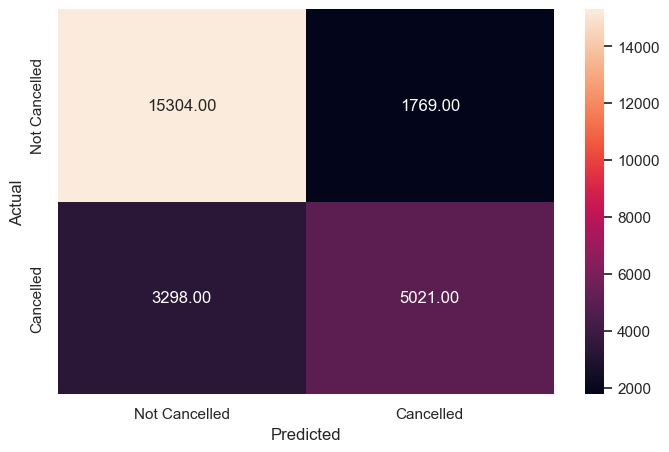

In [42]:
# Checking the performance on the training data
y_pred_train = lg.predict(X_train)
metrics_score(y_train, y_pred_train)

### *Insights* 
The code block predicts the target variable, 'y_train', with the use of the trained logistic regression model and the features from the training data. These predicted values are stored within the 'y_pred_train'. The 'metrics_score' function is called to evaluate the model's performance with different metrics like accuracy, precision, recall, F1-score, and so on.The precision scores measures the proportion of predicted positives that are actually correct (Kukil, 2022). The recall score measures how well the model remember or learn from the inputs of the user.

* It is shown in the metrics score that the precision for class 0, representing not canceled bookings, is at 82%. This means that 82% of the predicted not canceled bookings were indeed not canceled (True Positives). For cass 1, representing canceled bookings, the precision stands at 74% which means 74% of the predicted canceled bookings are truly canceled (True Negatives).
* There is 90% of the actual not cancelled cases were accurately predicted, while 60% of the actual canceled cases were correctly identified. 
* Class 0 or not canceled cases, boasts a higher F1 score at 86%, while class 1 has a score of 66%. The F1 score combines recall and precision to provide a balanced measure. 

It is evident that the accuracy of the machine learning model is 80%, which means this is the percentage that got all the booking status predictions right, whether they be positive or negative predictions. It is a good score, but it can still be improved since it has also been influenced by the class imbalance. It is evident that class 0 performs better in terms of precision, recall, and F1-score, while class 1 has relatively lower in recall, which implies that some actual cancellations were missed. While the model performs reasonably well overall, there are still areas of improvements, especially in correctly identifying canceled bookings. 

**Let's check the performance on the test set**

              precision    recall  f1-score   support

           0       0.82      0.89      0.85      7317
           1       0.73      0.59      0.65      3566

    accuracy                           0.79     10883
   macro avg       0.77      0.74      0.75     10883
weighted avg       0.79      0.79      0.79     10883



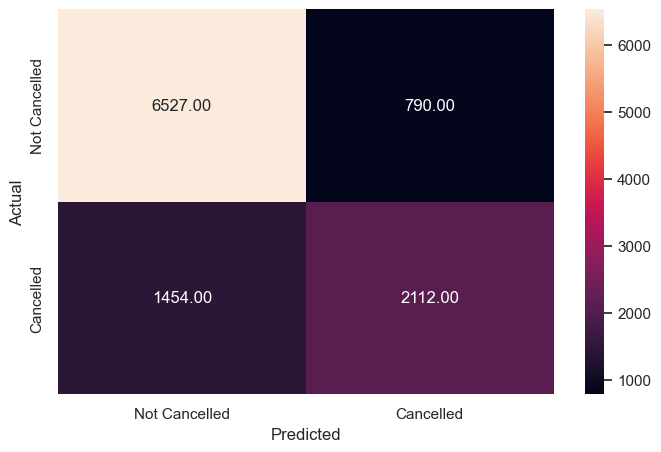

In [39]:
# Checking the performance on the test dataset
y_pred_test = lg.predict(X_test)
metrics_score(y_test, y_pred_test)

### *Insights*
The code block in the previous section checked the performance of the training data, whereas this time it will check the performance of the test data. 

* It is observed that the the precision of class 0 remains at 82% on both the training and test sets. However, the precision for class 1 is a bit lower on the test set at 73% compared to the training set. This indicates that there is a slight decrease in performance in determining true positives. 
* Similarly, the recall for class 0 has decreased on the test set at 89%, compared to the training set. This suggests that there has been a minor drop in the ability to identify true negatives. The recall for class 1 is also lower on the test set at 59% compared to the training set.   
* The F1 scores for class 0 and class 1 has slightly decreased compared to the training set, with values of 85% and 65%, respectively. 

While the scores were decent and reasonably consisent on both training and test datasets, there has been a slightly decreases in performance, especially on recall and F1-scores.


#### Find the optimal threshold for the model using the Precision-Recall Curve.

Precision-Recall curves summarize the trade-off between the true positive rate and the positive predictive value for a predictive model using different probability thresholds.

Let's use the Precision-Recall curve and see if we can find a **better threshold.**


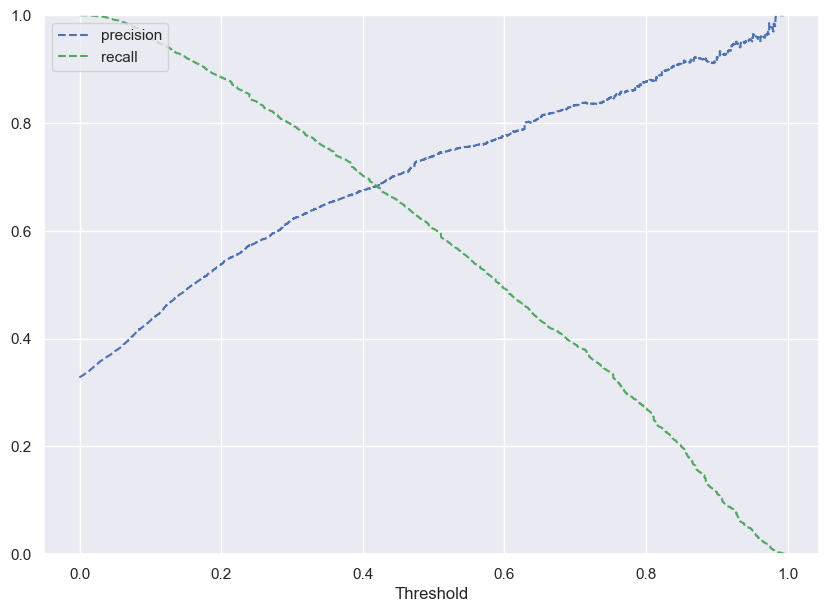

In [41]:
# Predict_proba gives the probability of each observation belonging to each class
y_scores_lg=lg.predict_proba(X_train)

precisions_lg, recalls_lg, thresholds_lg = precision_recall_curve(y_train, y_scores_lg[:, 1])

# Plot values of precisions, recalls, and thresholds
plt.figure(figsize=(10,7))
plt.plot(thresholds_lg, precisions_lg[:-1], 'b--', label='precision')
plt.plot(thresholds_lg, recalls_lg[:-1], 'g--', label = 'recall')
plt.xlabel('Threshold')
plt.legend(loc='upper left')
plt.ylim([0,1])
plt.show()

In [42]:
# Setting the optimal threshold
optimal_threshold = 0.25

### *Insights* 
The code block generates a precision-recall curve by adjusting the probability threshold as well as computing the precision and recall values accordingly. This is used to evaluate the performance of predicting booking cancellations. The 'predict_proba' function computes the predicted probabilities for each observation in the training data. The subsequent codes plot the values of precision, recall, and thresholds. 

The graph illustrates how recall and precision change with varying thresholds. Threshold involves developing binary decisions based on a certain threshold value (Admin, 2023). At an optimal threshold of 0.25, there is a balance between recall and precision. This intersection point is used to set a threshold that balances false positives and false negatives. The value of 0.25 is relatively low, which means it is more lenient in classifying bookings as cancellations. This threshold value corresponds to higher recall but lower precision. The balance is acceptable and moderate, but the model can strive for a higher optimal threshold value to improve its effectiveness and performance. 

#### Check the performance of the model on train and test data using the optimal threshold.

              precision    recall  f1-score   support

           0       0.90      0.70      0.79     17073
           1       0.58      0.84      0.69      8319

    accuracy                           0.75     25392
   macro avg       0.74      0.77      0.74     25392
weighted avg       0.79      0.75      0.76     25392



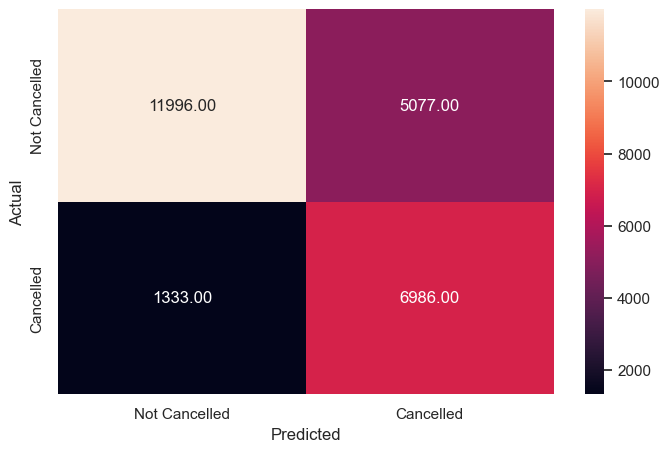

In [43]:
# Creating confusion matrix
y_pred_train = lg.predict_proba(X_train)
metrics_score(y_train, y_pred_train[:, 1] > optimal_threshold)

### *Insights*
The code block computes the model performance of the training data using the optimal threshold. It uses the 'predict_proba' function and compares these probabilities with an optimal threshold of 0.25. It then evaluates the metrics based on the modified predictions. 

This new model with the optimal threshold for train data has gained improvements compared to the initial model in class 0 precision, wherein it increased by 8%. The recall and F1-score of class 1 (canceled) have also substantially increased, which implies better identification of cancellations. The recall has increased by 24%, while the F1-score has increased by 3%. However, this comes at the cost of a decrease in class 0 (not canceled) recall and F1-scores, as well as class 1 precision, due to the trade-off of the optimal threshold. The accuracy has gotten lower by 5%. 

By increasing the threshold to 0.25, the new model have became more sensitive to the identification of canceled bookings, which led to improvements in the recall and F-1 score for class 1. However, it has decreased the performance for not-canceled bookings which is evident in the lesser recall and F-1 score.   

**Let's check the performance on the test set**

              precision    recall  f1-score   support

           0       0.90      0.70      0.79      7317
           1       0.57      0.83      0.68      3566

    accuracy                           0.74     10883
   macro avg       0.74      0.77      0.73     10883
weighted avg       0.79      0.74      0.75     10883



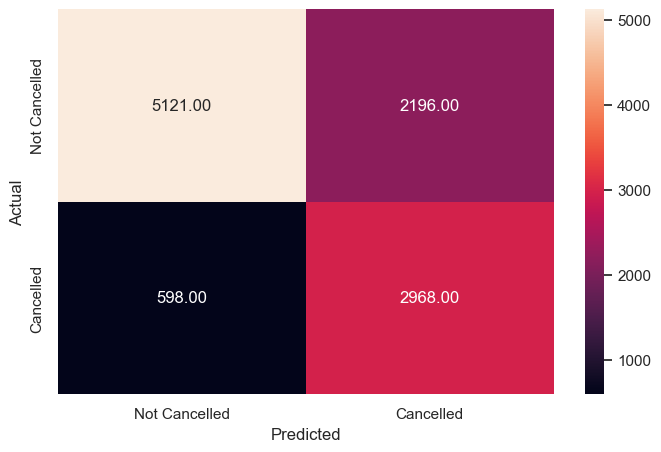

In [44]:
y_pred_test = lg.predict_proba(X_test)
metrics_score(y_test, y_pred_test[:, 1] > optimal_threshold)

### *Insights*
The code block is similar to the previous one, but in this case, it computes the model performance for test data. 

The new model with the optimal threshold of 0.25 for test data has also gained improvements compared to the initial model. The class 0 precision has increased by 8%. The recall and F1-score of class 1 have significantly increased by 24% and 3%, respectively. However, the recall and F1-score of class 0 have decreased due to the threshold. Same as well with the accuracy of the model, which has lowered by 5%. It is observed that the impact of the optimal threshold on the model's performance is similar or consistent on both the training and test sets. On both sets, the recall and F1-score for class 1 (Canceled) have increased which means that the new model has improved in correctly identifying a higher percentage of the actual canceled bookings. However, it also comes at the expense of other metrics like lower precision for class 1 and decreased F-1 score and recall for class 0. 

### Conclude ANY FOUR key takeaways for business recommendations 
1. A  more **consistent hotel cancellation policies** is recommended for INN Hotel Group to reduce the percentage of booking cancellations, prevent revenue losses, and optimize resource allocation. Current policies might be too lenient for bookers, especially for online bookings, wherein they can easily cancel their bookings in their own likings anytime.The hotel can introduce stricter non-refundable policy for short lead times and other scenarios. Colcol (2023) outlines some of the types of hotel cancellation policies: 
    * Non-Refundable Policy (for booking with lead time < 14 days) - to lock in those last-minute, high-risk bookings.
        * Reservations are non-refundable and non-changeable.
        * The full stay amount is charged at the time of booking. 
    * Seasonal Cancellation Policy (for peak periods, May to October) - since reselling rooms is more difficult in peak periods. 
        * Free cancellation for bookings made over 30 days before arrival. 
        * The full stay amount is charged when cancellations within 30 days of arrival. 
    * Long Stay Policy (for stay of 7 nights or more) - account for the higher cancellation trends with lengthier bookings.  
        * Free cancellation for bookings made over 60 days before arrival.
        * A two-night penalty is charged for cancellations within 60 days of arrival.
 ***
2. Since repeated guests have a notably low cancellation rate, **introducing loyalty programs** that provides rewards/benefits for new guests would help them move into that category. This would significantly increase guest retention. 
    * Value-Added Rewards - Offers perks like free breakfast, complimentary nights, access to exclusive events, or spa vouchers after booking a particular number of nights or spending at the hotel. 
    * Referral Programs - Encourage guests to refer friends and family with rewards for both the refferer and the new guest, like a large discount for amenities or subsequent hotel booking. Rewards can be redeemed and used within 12 months.
 ***

3. To mitigate high number of cancellations from online segments, **optimizing pricing strategies** is essential.  
    * A good recommendation for the hotel is to practice rate parity or price parity to ensure that the room rates offered by the hotel are consistent across all distribution channels (Hollander, 2023). Whether the guest booking on a third party online website, hotel website, or any distribution partner, the room prices will remain identical. In this way, it prevents the outliers and wide variance that is observed in online prices for online channel. 
    * Package pricing with attractive inclusions is another way to reduce the cancellations and enable markup up the total package rate. 
    * Offering discounts for longer stays (7+ days) will help reduce the cancellations among guests booking extended stays.  
  ***  
4. By continually employing logistic regression model, the INN Hotel Group can **identify which guests are more likely to cancel and which ones are not**, allowing them to take preventative actions like proving flexible booking options or offering benefits. The logistic regrssion model can be trained on the hotel's historical booking data and analyze patterns, which pinpoints factors or variables that correlate with a higher likelihood of cancellation. The hotel should adjust the model's precision and recall thresholds as per the hotel needs and ensure regular updates to maintain accuracy amidst the dynamic external factors and guest behavior.

## **PART 2**
In this section, you should discuss the validity of the real estate broker’s hypothesis and suggest the best course of action to your company President in dealing with his house in Florida.

Reesearch on prices of single-family homes in Florida yielded the Florida.csv dataset – with a sample of 15 metropolitan areas (in 1000 USD) for 2022 and 2023. 

At 5% level of significance, test to see if the evidence supports the real estate broker’s theory.

Let $\mu_1, \mu_2$ be the mean price of single-family homes in metropolitan areas of Florida for 2022 and 2023 respectively.

We want to test whether there is an increase in the house price from 2022 and 2023.

We will test the null hypothesis

>$H_0:\mu_1=\mu_2$

against the alternate hypothesis

>$H_a:\mu_1<\mu_2$

### *Insights*
The Quantum Insight's President is moving to the Philippines and is planning to sell his property in Miami, Florida. However, the real estate broker advised him not to sell the house since the prices of the houses have remained stagnant since last year. The Florida CSV file contains 15 metropolitan areas with prices of single-family homes in USD for the years 2022 and 2023. With a 5% level of significance, the goal is to test the real estate broker's hypothesis to see if there is evidence to support his claim of stagnant house prices. By providing statistical evidence, the analyst can provide the best course of action for the President.  

A significance level is the strength of evidence in probabilistic terms which is a crucial component of hypothesis testing (Frost, 2020). It is the threshold for whether the null hypothesis will be accepted or rejected. The significance level is usually 5% or 0.05, which is applied in this scenario. 

In this case, the null hypothesis (H0) assumes that the mean prices of the homes in metropolitan areas of Florida have no difference from 2022 to 2023, which supports the claim of the real estate broker that the prices are stagnant.

This will be tested against the alternative hypothesis (Ha), wherein it assumes that the mean prices of the homes in metropolitan areas of Florida have increased from 2022 to 2023, which opposes the real estate broker's claim.


In [28]:
houseprice = pd.read_csv("C:\\Users\\jayar\\Downloads\\FINALS DA\\Florida.csv")
houseprice.head()

,Metropolitan Area,Jan_2023,Jan_2022
0,Daytona Beach,117,96
1,Fort Lauderdale,207,169
2,Fort Myers,143,129
3,Fort Walton Beach,139,134
4,Gainesville,131,119


### *Insights*
The first line of code reads the Florida CSV file from the specified file path, and it is assigned to the variable 'houseprice'. Then, the '.head()' is executed to return the first 5 rows of the DataFrame. It displays a table containing the columns for 'Metropolitan Area', 'Jan_2023', and 'Jan_2022', revealing the corresponding prices of single-family homes for each metropolitan area in Florida for the years 2022 and 2023. Since the prices are denoted in 1000 USD, the values listed in the table are USD 117000, USD 96000, USD 207000, and so on. This table gives a quick overview of the price changes across the various Florida metropolitan areas over the given years. 

In [29]:
diff = np.mean(houseprice['Jan_2023'] - houseprice['Jan_2022'])
print('The mean of the differences between the house prices from 2022 to 2023', diff)

The mean of the differences between the house prices from 2022 to 2023 15.0


### *Insights*
The first line of code computes the mean (with NumPy library) by subtracting the 'Jan_2022' values from the 'Jan_2023' values for each data point in the 'houseprice' DataFrame, then calculates the means of the differences. The computed mean is assigned to the variable 'diff'. The mean is calculated to see if the average house price has changed over the years 2022 and 2023. This helps the analyst evaluate if the change in prices is statistically significant. 

The next line of code prints a statement or a set of strings that declares the computed mean and uses the variable 'diff'. The printed statement reveals that the mean difference in house prices between January 2022 and January 2023 is 15.0. This means that there's an increase in house prices of about 15,000 dollars (in 1000 USD) from 2022 to January 2023.

In [32]:
from scipy.stats import ttest_rel

### *Insights*

This code is executed to import the 'ttest_rel' function from the 'scip.stats' modules in the SciPy library. A 'ttest_rel' function is used to calculate the t-test on two related samples of scores, a and b, using the null hypothesis of identical average values (Scipy.Org, 2022). 

Specifically, a paired t-test or a dependent t-test is appropriate for the scenario. A paired t-test is used when there is paired data, such as before and after measurements (Zebra Bi, 2023). 


* In this case, the before measurement is the house price in January 2022, and the after measurement is the house price in January 2023. This is considered to be the paired data that aligns with the characteristics of the paired t-test.

* A t-test can be done if the objective is to test the significant difference in paired or dependent measurements (Bevans, 2020). The data is composed of house prices for the same 15 metropolitan areas for both 2022 and 2023. Each of these areas has two corresponding house prices for both years, which are considered to be dependent on or related to each other. 

* According to Frost (2021), the t-test can be used to determine if the mean change for these pairs is significantly different from zero. The objective of the statistical problem is to identify if the mean difference in house prices between 2023 and 2022 is significantly different from zero, which aligns with the goal of testing the null hypothesis against the alternative hypothesis. 

* From the same source, a paired t-test can be used if the groups come from a single population. Since the metropolitan areas are all located in Florida, it is considered a single population, and the house prices or measurements are taken from the same areas at two different periods. 

* Lastly, the paired t-test is used to compare measurements under two different conditions (Frost, 2021). This is very similar to the scenario wherein it involves comparing house prices in two different time lines or conditions: years 2022 and 2023. 

By employing a t-test in the analysis, it can account for the pairing or dependency of the observations, which also addresses the statistical problem of whether there is a significant increase in house prices from different periods, January 2022 to 2023, across the metropolitan areas in Florida. With these justifications, the paired t-test is the most appropriate and suitable statistical test to address the scenario and provide the best course of action. 


In [33]:
test_stat, p_value = ttest_rel(houseprice['Jan_2022'], houseprice['Jan_2023'], alternative = 'less')
print('The p-value is ', p_value)

The p-value is  8.282698151615477e-05


### *Conclusion*

A p-value quantifies the evidence against a null hypothesis (Mcleod, 2023). A low p-value implies that the data is inconsistent with the null hypothesis, which possibly favors the alternative hypothesis. In the output, the p-value (8.282698151615477e-05) is significantly lower than the significance level of 5% or 0.05. According to Bobbit (2019), a p-value that is lower than the significant level means that the null hypothesis can be rejected (𝐻0:𝜇1=𝜇2). It also means that there is adequate evidence to support the alternative hypothesis (𝐻𝑎:𝜇1<𝜇2). The analyst can conclude that the house prices of single-family homes in Florida metropolitan areas have greatly increased from January 2022 to January 2023 (alternative hypothesis), wherein this finding opposes the claim of the real estate broker's theory of stagnant house prices (null hypothesis). Therefore, it is advantageous for the President to sell the property in Miami, Florida, while the price has increased. Given this important evidence, the analyst can suggest a course of action for the President.  

It is a good opportunity to sell the President's property in Miami since there is a trend that house prices are rising, which can also potentially yield property appreciation. Although the evidence shows that there is an increase in prices, the analyst did not include predicting the future prices of the houses. Therefore, it is advisable to not delay the sale so that the President can capitalize on this increase in prices, because if the President prolongs the sale, he may lose the opportunity to sell the property at higher price and in favorable market conditions. Aside from the house price, it is worth noting that the decision to sell the property must also take into account other factors like market conditions (interest rate, current property market) and property conditions (curb appeal) to maximize the profit from the investment (Property24 and Suburban Mum, 2024). 

### *References*


Summary Statistics (Analysis)—ArcGIS Pro | Documentation. (2024) [Online] Arcgis.com. Available from : https://pro.arcgis.com/en/pro-app/latest/tool-reference/analysis/summary-statistics.htm. [Accessed 27/04/24].

Box Plot Explained: Interpretation, Examples, & Comparison. (2023) [Online] Simply Psychology. Available from : https://www.simplypsychology.org/boxplots.html [Accessed 27/04/24].

Byju (2017) Histogram - Definition, Types, Graph, and Examples. [Online] BYJUS. Available from : https://byjus.com/maths/histogram/ [Accessed 29/04/24].

Understanding and using Box and Whisker Plots. (2017) [Online] Tableau. Available from : https://www.tableau.com/data-insights/reference-library/visual-analytics/charts/box-whisker [Accessed 27/04/24].

Rezek, H. (2024) A Guide to Data Manipulation with Python’s Pandas and NumPy. [Online] Medium. Available from : https://medium.com/munchy-bytes/a-guide-to-data-manipulation-with-pythons-pandas-and-numpy-607cfc62fba7 [Accessed 27/04/24].

GeeksforGeeks (2020) Data Visualisation in Python using Matplotlib and Seaborn. [Online] GeeksforGeeks. Available from : https://www.geeksforgeeks.org/data-visualisation-in-python-using-matplotlib-and-seaborn/ [Accessed 27/04/24].

scikit-learn: machine learning in Python — scikit-learn 1.4.2 documentation. (2024) [Online] Scikit-learn.org. Available from : https://scikit-learn.org/stable/index.html [Accessed 27/04/24].

Solanki, S. (2021) warnings - Simple Guide to Handle Warning Messages in Python. [Online] Coderzcolumn.com. Available from : https://coderzcolumn.com/tutorials/python/warnings-simple-guide-to-handle-warning-messages-in-python [Accessed 27/04/24].

Frost, J. (2020) Understanding Significance Levels in Statistics. [Online] Statistics By Jim. Available from : https://statisticsbyjim.com/hypothesis-testing/significance-levels/ [Accessed 28/04/24].

scipy.stats.ttest_rel — SciPy v1.8.0 Manual. (2022) [Online] Scipy.org. Available from : https://docs.scipy.org/doc//scipy-1.8.0/reference/generated/scipy.stats.ttest_rel.html [Accessed 28/04/24].

How to Do a T Test in Excel - Zebra BI. (2023) [Online] Zebra BI. Available from : https://zebrabi.com/guide/how-to-do-a-t-test-in-excel/ [Accessed 28/04/24].

Frost, J. (2021) Paired T Test: Definition & When to Use It. [Online] Statistics By Jim. Available from : https://statisticsbyjim.com/hypothesis-testing/paired-t-test/ [Accessed 28/04/24].

Understanding P-Values and Statistical Significance. (2023) [Online] Simply Psychology. Available from : https://www.simplypsychology.org/p-value.html [Accessed 28/04/24].

Bobbitt, Z. (2019) An Explanation of P-Values and Statistical Significance - Statology. [Online] Statology. Available from : https://www.statology.org/p-values-statistical-significance/ [Accessed 28/04/24].

Suburban Mum (2024) 6 key factors to consider when it comes to selling your property | Suburban Mum. [Online] Suburban Mum. Available from : https://suburban-mum.com/6-key-factors-to-consider-when-it-comes-to-selling-your-property/ [Accessed 28/04/24].

Considerations when selling a home - Property24. (2024) [Online] Property24.com. Available from : https://www.property24.com/property101/sellers-guide/considerations-when-selling-a-home/15905 [Accessed 28/04/24].

GeeksforGeeks (2020) Countplot using seaborn in Python. [Online] GeeksforGeeks. Available from : https://www.geeksforgeeks.org/countplot-using-seaborn-in-python/ [Accessed 28/04/24].

Loves, N. (2021) Nicky Loves Data. [Online] Nicky Loves Data. Available from : https://www.nickylovesdata.com/blog/count-plots-and-bar-plots [Accessed 29/04/24].

Train and Test datasets in Machine Learning - Javatpoint. (2021) [Online] www.javatpoint.com. Available from : https://www.javatpoint.com/train-and-test-datasets-in-machine-learning [Accessed 01/05/24].

GeeksforGeeks (2020) Python Pandas getdummies() method. [Online] GeeksforGeeks. Available from : https://www.geeksforgeeks.org/python-pandas-get_dummies-method/ [Accessed 01/05/24].

AI Summary (2023) Understanding The F1 Score In Machine Learning - AI Summary. [Online] AI Summary. Available from : https://www.ai-summary.com/understanding-the-f1-score-in-machine-learning/ [Accessed 01/05/24].

GeeksforGeeks (2023) F1 Score in Machine Learning. [Online] GeeksforGeeks. Available from : https://www.geeksforgeeks.org/f1-score-in-machine-learning/ [Accessed 01/05/24].

GeeksforGeeks (2017) Logistic Regression in Machine Learning. [Online] GeeksforGeeks. Available from : https://www.geeksforgeeks.org/understanding-logistic-regression/ [Accessed 01/05/24].

Kukil (2022) in Object Detection. (2022) [Online] LearnOpenCV – Learn OpenCV, PyTorch, Keras, Tensorflow with code, & tutorials. Available from : https://learnopencv.com/mean-average-precision-map-object-detection-model-evaluation-metric/ [Accessed 01/05/24].

Admin (2023) Thresholding in Machine Learning | PythonProg. [Online] PythonProg. Available from : https://www.pythonprog.com/thresholding-in-machine-learning/[Accessed 01/05/24].

Super User (2020) When (and Why) to use Heat Maps. [Online] Dundas.com. Available from : https://www.dundas.com/resources/blogs/best-practices/when-and-why-to-use-heat-map [Accessed 01/05/24].

seaborn.heatmap — seaborn 0.13.2 documentation. (2024) [Online] Pydata.org. Available from : https://seaborn.pydata.org/generated/seaborn.heatmap.html [Accessed 01/05/24].

Kenton (2024) [Online] Investopedia. Available from : https://www.investopedia.com/terms/h/heatmap.asp

Correlation Coefficients: Positive, Negative, and Zero. (2024) [Online] Investopedia. Available from : https://www.investopedia.com/ask/answers/032515/what-does-it-mean-if-correlation-coefficient-positive-negative-or-zero.asp

What is Rate Parity in the Hotel Industry? (2021) [Online] Hotel Tech Report. Available from : https://hoteltechreport.com/news/rate-parity [Accessed 03/05/24].
